# Faz 4a — Karar Bloğu: Hangi Eksen Kalacak?

## Faz 3'ün ortaya çıkardığı çelişki

| Ölçü | Değer |
|---|---|
| gafgyt:tcp ROC-AUC | **0,9714** |
| gafgyt:tcp TPR @ nominal %1 FPR | **0,1119** |
| Saldırı / normal medyan hata oranı | 5× -- 470× |

Model saldırıyı net biçimde ayırıyor ama kendi çalışma noktasında yakalamıyor.
Sorun temsilde değil, **eşikte**.

## Bu notebook'un cevaplayacağı beş soru

1. **Eşik neden şişiyor?** Ağır kuyruk mu, zamansal kayma mı, ikisi mi?
2. **Ne kadar kazanç var?** Eşik mükemmel seçilseydi tavan nerede olurdu?
3. **Basit düzeltmeler işe yarıyor mu?** Altı farklı eşik stratejisi karşılaştırılıyor.
4. **Kişiselleştirme primi eşik düzeltilince hayatta kalıyor mu?** *(belirleyici test)*
5. **Gürültü tabanı bu ölçümlerin neresinde?**

Dördüncü soru çalışmanın eksenini belirliyor:

- **Prim kayboluyorsa** → asıl bulgu eşik kalibrasyonudur, kişiselleştirme destekleyici
  bölüme iner.
- **Prim duruyorsa** → iki eksen de korunur, birbirinden bağımsız iki katkı olur.

---

### Neden yeniden eğitim gerekiyor

Faz 2 checkpoint'i yalnızca *test dilimi* hatalarını ve eşik değerini sakladı.
Kayma analizi için kalibrasyon ve eşik dilimlerinin hataları da gerekiyor.
Bu yüzden 10 model (9 cihaz + 1 küresel) iki tohumla yeniden eğitiliyor ve
**tüm dilimlerin hataları kaydediliyor**. Yaklaşık 10-15 dakika.

## 0. Ortam

In [1]:
import sys, os, glob, time, json, pickle, random, warnings
from collections import defaultdict

_PYLIBS = os.path.expanduser("~/work/pylibs")
if os.path.isdir(_PYLIBS) and _PYLIBS not in sys.path:
    sys.path.insert(0, _PYLIBS)
for v in ("OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS"):
    os.environ[v] = "8"
os.environ["CUDA_CACHE_PATH"] = os.path.expanduser("~/work/.cuda_cache")
os.makedirs(os.environ["CUDA_CACHE_PATH"], exist_ok=True)

import ctypes
try:
    import nvidia
    libdirs = sorted(glob.glob(os.path.join(os.path.dirname(nvidia.__file__), "*", "lib")))
    os.environ["LD_LIBRARY_PATH"] = ":".join(libdirs) + ":" + os.environ.get("LD_LIBRARY_PATH","")
    n = 0
    for d in libdirs:
        for so in sorted(glob.glob(os.path.join(d, "*.so*"))):
            try: ctypes.CDLL(so, mode=ctypes.RTLD_GLOBAL); n += 1
            except OSError: pass
    print(f"{n} CUDA kutuphanesi on-yuklendi")
except ImportError:
    print("CPU")

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt; import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import roc_auc_score
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
matplotlib.rcParams["figure.dpi"] = 60
matplotlib.rcParams["savefig.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

31 CUDA kutuphanesi on-yuklendi


I0000 00:00:1790689708.560976 1078718 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790689708.586904 1078718 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1790689709.070320 1078718 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1790689709.241100 1078718 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
KOK = os.path.expanduser("~/work/IoT_Botnet/veri/nbaiot")
OUT = os.path.expanduser("~/work/IoT_Botnet/faz4a_ciktilar")
for s in ("figures","tables"): os.makedirs(f"{OUT}/{s}", exist_ok=True)
CKPT = f"{OUT}/faz4a_checkpoint.pkl"

SEEDLER = [42, 7]
EPOCHS, BATCH, PATIENCE, LR, KOD = 60, 256, 8, 1e-3, 16
KALIBRASYON, ESIK_DILIM = 0.60, 0.10
HEDEF_FPR = 0.01
SALDIRI_TEST = 30_000
ZOR = ["gafgyt:tcp", "gafgyt:udp"]

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    os.environ["PYTHONHASHSEED"] = str(s)
def savefig(a):
    plt.savefig(f"{OUT}/figures/{a}.png"); plt.show()
print("Cikti:", OUT)

Cikti: /home/jovyan/work/IoT_Botnet/faz4a_ciktilar


In [3]:
def bilgi(y):
    p = os.path.relpath(y, KOK).split(os.sep)
    if len(p) == 2: return p[0], "benign", "benign"
    return p[0], p[1].replace("_attacks",""), os.path.splitext(p[-1])[0]

dosyalar = [f for f in sorted(glob.glob(f"{KOK}/**/*.csv", recursive=True))
            if "demonstrate" not in f]
t0 = time.time(); IYI, SALDIRI = {}, defaultdict(dict)
for f in dosyalar:
    c, a, t = bilgi(f)
    df = pd.read_csv(f, dtype="float32")
    if a == "benign": IYI[c] = df.to_numpy()
    else: SALDIRI[c][f"{a}:{t}"] = df.to_numpy()[:SALDIRI_TEST]

OZN = list(pd.read_csv(dosyalar[0], nrows=1).columns)
CIHAZLAR = sorted(IYI)
def bol(A):
    n=len(A); i1=int(KALIBRASYON*n); i2=int((KALIBRASYON+ESIK_DILIM)*n)
    return A[:i1], A[i1:i2], A[i2:]
BOLUM = {c: dict(zip(("kal","esik","test"), bol(IYI[c]))) for c in CIHAZLAR}
print(f"Yuklendi ({time.time()-t0:.0f}s) | {len(CIHAZLAR)} cihaz")

Yuklendi (28s) | 9 cihaz


## 1. Modellerin yeniden eğitimi ve tam kayıt

In [4]:
def ae(boyut, tohum):
    set_seed(tohum)
    i = layers.Input(shape=(boyut,))
    x = layers.Dense(64, activation="relu")(i)
    x = layers.Dense(32, activation="relu")(x)
    k = layers.Dense(KOD, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(k)
    x = layers.Dense(64, activation="relu")(x)
    m = models.Model(i, layers.Dense(boyut, activation="linear")(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="mse")
    return m

def egit(kal, tohum):
    mu, sd = kal.mean(0), kal.std(0) + 1e-8
    X = np.clip((kal-mu)/sd, -20, 20).astype("float32")
    nv = max(1, int(0.1*len(X)))
    m = ae(X.shape[1], tohum)
    m.fit(X[:-nv], X[:-nv], validation_data=(X[-nv:], X[-nv:]),
          epochs=EPOCHS, batch_size=BATCH, verbose=0,
          callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True)])
    return m, mu, sd

def hata(m, mu, sd, A):
    X = np.clip((A-mu)/sd, -20, 20).astype("float32")
    R = m.predict(X, batch_size=4096, verbose=0)
    return np.mean((X-R)**2, axis=1).astype("float32")

In [5]:
if os.path.exists(CKPT):
    with open(CKPT,"rb") as f: H = pickle.load(f)
    print(f"Onceki kayit: {len(H)} anahtar")
else:
    H = {}
    print("Yeni kosu")

t0 = time.time()
for tohum in SEEDLER:
    # --- D-D: cihaz basina ---
    for c in CIHAZLAR:
        k = ("D-D", c, tohum)
        if k in H: continue
        m, mu, sd = egit(BOLUM[c]["kal"], tohum)
        H[k] = {"kal": hata(m,mu,sd,BOLUM[c]["kal"]),
                "esik": hata(m,mu,sd,BOLUM[c]["esik"]),
                "test": hata(m,mu,sd,BOLUM[c]["test"]),
                "sal": {t: hata(m,mu,sd,A) for t,A in SALDIRI[c].items()}}
        del m; tf.keras.backend.clear_session()
        print(f"  D-D  tohum={tohum}  {c[:34]}")
        with open(CKPT,"wb") as f: pickle.dump(H, f)

    # --- G-G: tek kuresel model ---
    if ("G-G", CIHAZLAR[0], tohum) not in H:
        kal = np.concatenate([BOLUM[c]["kal"] for c in CIHAZLAR])
        m, mu, sd = egit(kal, tohum)
        for c in CIHAZLAR:
            H[("G-G", c, tohum)] = {
                "kal": hata(m,mu,sd,BOLUM[c]["kal"]),
                "esik": hata(m,mu,sd,BOLUM[c]["esik"]),
                "test": hata(m,mu,sd,BOLUM[c]["test"]),
                "sal": {t: hata(m,mu,sd,A) for t,A in SALDIRI[c].items()}}
        del m; tf.keras.backend.clear_session()
        print(f"  G-G  tohum={tohum}  (9 cihaz degerlendirildi)")
        with open(CKPT,"wb") as f: pickle.dump(H, f)

print(f"\nSure: {(time.time()-t0)/60:.1f} dk | {len(H)} kayit")

Yeni kosu


W0000 00:00:1790689737.125580 1078718 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790689737.207813 1078718 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 771 MB memory:  -> device: 0, name: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, pci bus id: 0000:02:00.0, compute capability: 12.0a
I0000 00:00:1790689738.117930 1078887 service.cc:153] XLA service 0x72f0340343f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790689738.117966 1078887 service.cc:161]   StreamExecutor [0]: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790689738.136419 1078887 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `

  D-D  tohum=42  Danmini_Doorbell


I0000 00:00:1790689765.828366 1078887 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28986__.9
I0000 00:00:1790689766.805587 1078884 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28986__.9
I0000 00:00:1790689767.324929 1078884 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790689767.711031 1078884 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790689768.169085 1078884 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a goo

  D-D  tohum=42  Ecobee_Thermostat


...

  D-D  tohum=7  SimpleHome_XCS7_1002_WHT_Security_


I0000 00:00:1790690197.893381 1078889 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_820139__.9
I0000 00:00:1790690198.870827 1078889 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_820139__.9


  D-D  tohum=7  SimpleHome_XCS7_1003_WHT_Security_


I0000 00:00:1790690209.647734 1078889 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_834654__.9
I0000 00:00:1790690212.042478 1078890 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_834654__.9


  G-G  tohum=7  (9 cihaz degerlendirildi)

Sure: 9.5 dk | 36 kayit


## 2. Soru 1 — Eşik neden şişiyor?

Üç aday açıklama var:

**Ağır kuyruk.** İyi huylu hataların dağılımında az sayıda aşırı değer var; %99'luk dilim
bunlardan etkileniyor.

**Zamansal kayma.** Model verinin ilk %60'ıyla eğitiliyor, eşik sonraki %10'dan seçiliyor.
Cihazın davranışı bu aralıkta değiştiyse o dilimdeki normal kayıtlar modele göre anormal
görünüyor.

**İkisi birden.**

Ayırt etmek için eşik dilimindeki hataları, kalibrasyon dilimindekiyle karşılaştırıyoruz.
Kayma varsa eşik dilimi belirgin biçimde yüksek olmalı.

In [6]:
satir = []
for c in CIHAZLAR:
    for tohum in SEEDLER:
        h = H.get(("D-D", c, tohum))
        if h is None: continue
        kal, esk, tst = h["kal"], h["esik"], h["test"]
        zor = np.concatenate([h["sal"][t] for t in ZOR if t in h["sal"]]) \
              if any(t in h["sal"] for t in ZOR) else np.array([])
        satir.append({
            "cihaz": c, "tohum": tohum,
            "kal_medyan": float(np.median(kal)),
            "esik_medyan": float(np.median(esk)),
            "test_medyan": float(np.median(tst)),
            "kayma_orani": float(np.median(esk)/(np.median(kal)+1e-12)),
            "kal_q99": float(np.quantile(kal, 0.99)),
            "esik_q99": float(np.quantile(esk, 0.99)),
            "kuyruk_agirligi": float(np.quantile(esk,0.99)/(np.median(esk)+1e-12)),
            "zor_medyan": float(np.median(zor)) if len(zor) else np.nan,
        })
tani = pd.DataFrame(satir)
ort = tani.groupby("cihaz").mean(numeric_only=True).drop(columns=["tohum"])
ort["zor_esik_q99_orani"] = ort.zor_medyan / ort.esik_q99
ort.to_csv(f"{OUT}/tables/f4a_tablo1_esik_tanisi.csv")
ort.index = [i[:28] for i in ort.index]
print(ort[["kayma_orani","kuyruk_agirligi","zor_esik_q99_orani"]].round(3).to_string())
print("\nkayma_orani      : esik diliminin medyani / kalibrasyon medyani (1'e yakin = kayma yok)")
print("kuyruk_agirligi  : esik diliminin q99'u / medyani  (buyuk = agir kuyruk)")
print("zor_esik_q99_orani: zor saldirinin medyani / esik degeri  (>1 ise yakalanmali)")

                              kayma_orani  kuyruk_agirligi  zor_esik_q99_orani
Danmini_Doorbell                    1.039          130.402               3.455
Ecobee_Thermostat                   1.062           14.737               0.504
Ennio_Doorbell                      0.591           94.744               0.462
Philips_B120N10_Baby_Monitor        1.219          302.666               0.317
Provision_PT_737E_Security_C        1.042           58.581               0.747
Provision_PT_838_Security_Ca        1.336           37.004               0.407
Samsung_SNH_1011_N_Webcam           1.873          396.374               0.133
SimpleHome_XCS7_1002_WHT_Sec        1.282          141.051               0.405
SimpleHome_XCS7_1003_WHT_Sec        1.069          522.485               0.321

kayma_orani      : esik diliminin medyani / kalibrasyon medyani (1'e yakin = kayma yok)
kuyruk_agirligi  : esik diliminin q99'u / medyani  (buyuk = agir kuyruk)
zor_esik_q99_orani: zor saldirinin medyani / esi

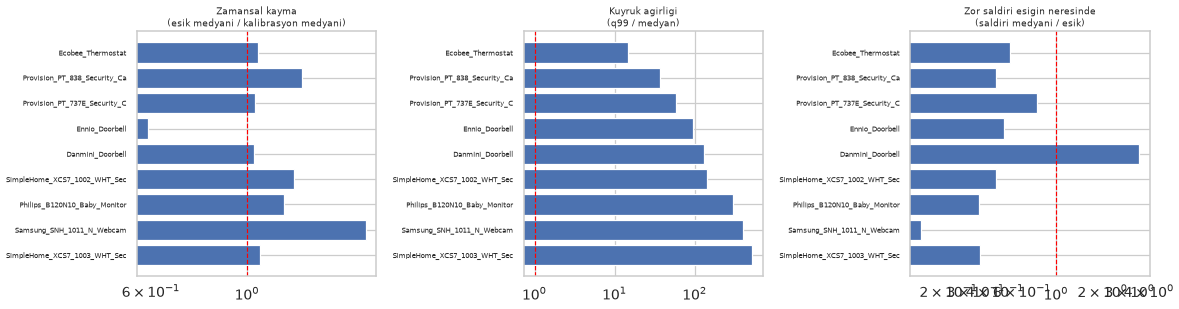

Kirmizi cizginin SAGINDA olmak:
  1. panel: zamansal kayma var
  2. panel: agir kuyruk var
  3. panel: saldiri esigin uzerinde -> yakalanmali (ama Faz 2'de yakalanmadi)


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
o = ort.sort_values("kuyruk_agirligi", ascending=False)
for a, sut, bas, cizgi in zip(
        ax, ["kayma_orani","kuyruk_agirligi","zor_esik_q99_orani"],
        ["Zamansal kayma\n(esik medyani / kalibrasyon medyani)",
         "Kuyruk agirligi\n(q99 / medyan)",
         "Zor saldiri esigin neresinde\n(saldiri medyani / esik)"],
        [1.0, 1.0, 1.0]):
    a.barh(range(len(o)), o[sut], color="#4c72b0")
    a.axvline(cizgi, color="red", ls="--", lw=1.4)
    a.set_yticks(range(len(o))); a.set_yticklabels(o.index, fontsize=8)
    a.set_xscale("log"); a.set_title(bas, fontsize=11)
plt.tight_layout(); savefig("f4a_fig01_esik_tanisi")

print("Kirmizi cizginin SAGINDA olmak:")
print("  1. panel: zamansal kayma var")
print("  2. panel: agir kuyruk var")
print("  3. panel: saldiri esigin uzerinde -> yakalanmali (ama Faz 2'de yakalanmadi)")

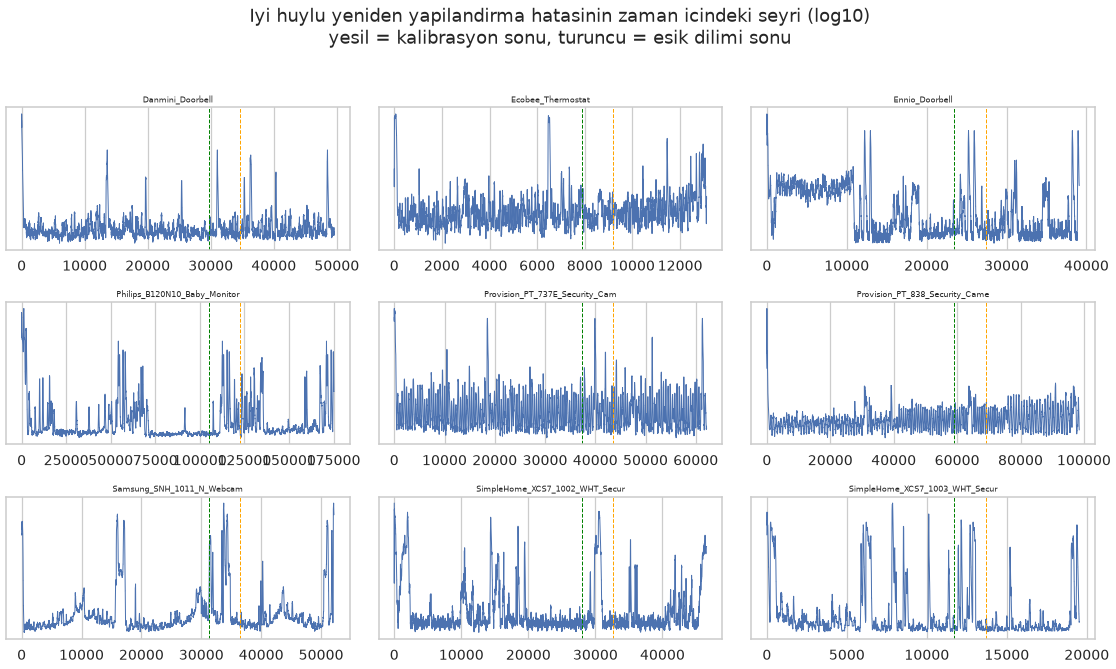

In [8]:
# ---- Iyi huylu hatanin zaman icindeki seyri ----------------------------
fig, axes = plt.subplots(3, 3, figsize=(19, 11))
for a, c in zip(axes.ravel(), CIHAZLAR):
    h = H.get(("D-D", c, SEEDLER[0]))
    if h is None: continue
    tum = np.concatenate([h["kal"], h["esik"], h["test"]])
    n = len(tum); k = max(1, n // 400)
    kayan = pd.Series(tum).rolling(k, min_periods=1).median().to_numpy()
    a.plot(np.arange(n), np.log10(kayan + 1e-12), lw=1.2, color="#4c72b0")
    a.axvline(len(h["kal"]), color="green", ls="--", lw=1.2)
    a.axvline(len(h["kal"])+len(h["esik"]), color="orange", ls="--", lw=1.2)
    a.set_title(c[:30], fontsize=10); a.set_yticks([])
plt.suptitle("Iyi huylu yeniden yapilandirma hatasinin zaman icindeki seyri (log10)\n"
             "yesil = kalibrasyon sonu, turuncu = esik dilimi sonu", y=1.02)
plt.tight_layout(); savefig("f4a_fig02_kayma")

## 3. Soru 2 — Tavan nerede? (kahin eşiği)

**Kahin eşiği**, test kümesindeki iyi huylu veriye bakarak tam %1 yanlış alarm verecek
şekilde seçilen eşiktir. Gerçekte kullanılamaz (test verisini görmek gerekir) ama
**eşik düzeltmesinin üst sınırını** verir.

Mevcut eşikle kahin eşiği arasındaki fark, eşik çalışmasının değerini gösterir.

In [9]:
def olc(h, esik):
    tum = np.concatenate(list(h["sal"].values()))
    zor = [h["sal"][t] for t in ZOR if t in h["sal"]]
    r = {"TPR": float((tum > esik).mean()),
         "FPR": float((h["test"] > esik).mean())}
    if zor:
        Z = np.concatenate(zor)
        r["TPR_zor"] = float((Z > esik).mean())
    return r

satir = []
for c in CIHAZLAR:
    for tohum in SEEDLER:
        h = H.get(("D-D", c, tohum))
        if h is None: continue
        mevcut = float(np.quantile(h["esik"], 1-HEDEF_FPR))
        kahin  = float(np.quantile(h["test"], 1-HEDEF_FPR))
        satir.append({"cihaz": c, "tohum": tohum, "esik_tipi": "mevcut (q99 esik dilimi)",
                      "esik": mevcut, **olc(h, mevcut)})
        satir.append({"cihaz": c, "tohum": tohum, "esik_tipi": "kahin (test uzerinde %1 FPR)",
                      "esik": kahin, **olc(h, kahin)})
kah = pd.DataFrame(satir)
kah.to_csv(f"{OUT}/tables/f4a_tablo2_kahin.csv", index=False)
print(kah.groupby("esik_tipi")[["TPR","TPR_zor","FPR"]].mean().round(4).to_string())

p = kah.groupby(["cihaz","esik_tipi"])[["TPR_zor"]].mean().unstack()
p.index = [i[:28] for i in p.index]
print("\nZor turlerde yakalama orani:\n")
print((p*100).round(2).to_string())

                                 TPR  TPR_zor     FPR
esik_tipi                                            
kahin (test uzerinde %1 FPR)  0.7971   0.2228  0.0100
mevcut (q99 esik dilimi)      0.7747   0.1117  0.0096

Zor turlerde yakalama orani:

                                                  TPR_zor                         
esik_tipi                    kahin (test uzerinde %1 FPR) mevcut (q99 esik dilimi)
Danmini_Doorbell                                   100.00                   100.00
Ecobee_Thermostat                                    0.09                     0.09
Ennio_Doorbell                                       0.09                     0.09
Philips_B120N10_Baby_Monitor                         0.04                     0.04
Provision_PT_737E_Security_C                        50.04                     0.07
Provision_PT_838_Security_Ca                         0.10                     0.07
Samsung_SNH_1011_N_Webcam                            0.04                     0.02
Simple

## 4. Soru 3 — Basit düzeltmeler işe yarıyor mu?

Altı eşik stratejisi. Hepsi **yalnızca iyi huylu veriye** dayanıyor, yani gerçekte
kullanılabilir (kahin hariç).

| Strateji | Tanım |
|---|---|
| `q99_esik` | Eşik diliminin %99'luk değeri *(mevcut)* |
| `q99_kal` | Kalibrasyon diliminin %99'luk değeri |
| `q99_budanmis` | Eşik diliminin en yüksek %1'i atıldıktan sonra %99'luk değer |
| `medyan_3mad` | Medyan + 3 × ortanca mutlak sapma |
| `medyan_6mad` | Medyan + 6 × ortanca mutlak sapma |
| `log_q99` | Logaritmik uzayda ortalama + 2,33 standart sapma |
| `kahin` | *(üst sınır, gerçekte kullanılamaz)* |

Ortanca mutlak sapma (MAD), standart sapmanın aşırı değerlere dayanıklı karşılığıdır.
Ağır kuyruklu dağılımlarda yüzdelik dilimlerden çok daha kararlıdır.

In [10]:
def mad(x):
    m = np.median(x)
    return float(np.median(np.abs(x - m)))

def esikler(h):
    e, k, t = h["esik"], h["kal"], h["test"]
    med, s = float(np.median(e)), mad(e)
    kes = np.quantile(e, 0.99)
    budanmis = e[e <= kes]
    le = np.log10(e + 1e-12)
    return {
        "q99_esik":     float(np.quantile(e, 0.99)),
        "q99_kal":      float(np.quantile(k, 0.99)),
        "q99_budanmis": float(np.quantile(budanmis, 0.99)),
        "medyan_3mad":  med + 3*s,
        "medyan_6mad":  med + 6*s,
        "log_q99":      float(10 ** (le.mean() + 2.33*le.std())),
        "kahin":        float(np.quantile(t, 1-HEDEF_FPR)),
    }

satir = []
for yap in ["D-D", "G-G"]:
    for c in CIHAZLAR:
        for tohum in SEEDLER:
            h = H.get((yap, c, tohum))
            if h is None: continue
            for ad, e in esikler(h).items():
                satir.append({"yapilandirma": yap, "cihaz": c, "tohum": tohum,
                              "strateji": ad, "esik": e, **olc(h, e)})
strat = pd.DataFrame(satir)
strat.to_csv(f"{OUT}/tables/f4a_tablo3_stratejiler.csv", index=False)

SIRA = ["q99_esik","q99_kal","q99_budanmis","medyan_3mad","medyan_6mad","log_q99","kahin"]
oz = (strat[strat.yapilandirma=="D-D"].groupby("strateji")[["TPR","TPR_zor","FPR"]]
      .mean().reindex(SIRA).round(4))
oz["FPR_sapma"] = (oz.FPR - HEDEF_FPR).abs().round(4)
print("D-D modelleri, eşik stratejisine göre:\n")
print(oz.to_string())

D-D modelleri, eşik stratejisine göre:

                 TPR  TPR_zor     FPR  FPR_sapma
strateji                                        
q99_esik      0.7747   0.1117  0.0096     0.0004
q99_kal       0.8082   0.2783  0.0119     0.0019
q99_budanmis  0.8195   0.2783  0.0166     0.0066
medyan_3mad   1.0000   1.0000  0.2143     0.2043
medyan_6mad   1.0000   1.0000  0.1436     0.1336
log_q99       0.8419   0.3893  0.0196     0.0096
kahin         0.7971   0.2228  0.0100     0.0000


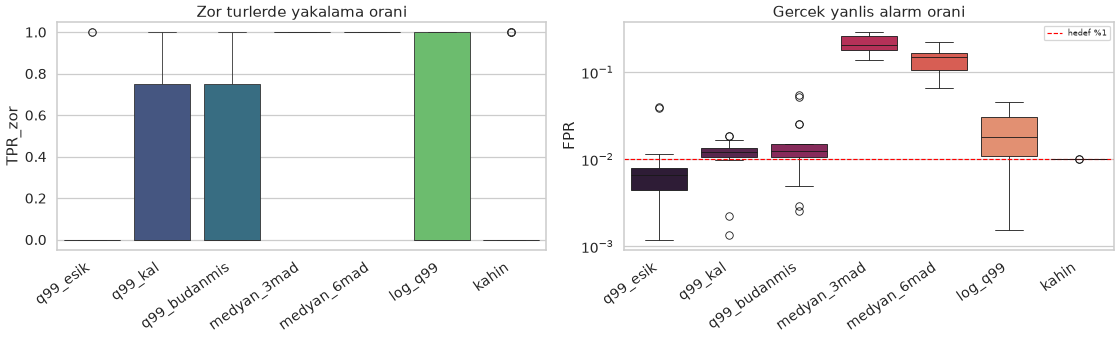

Bir strateji ise yarar sayilir ancak: TPR_zor yuksek VE FPR hedefe yakinsa.
Yuksek TPR'yi FPR'yi patlatarak elde etmek kazanc degildir.


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(19, 6))
alt = strat[strat.yapilandirma=="D-D"]
sns.boxplot(data=alt, x="strateji", y="TPR_zor", order=SIRA,
            hue="strateji", palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Zor turlerde yakalama orani"); ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=35)
for l in ax[0].get_xticklabels(): l.set_ha("right")

sns.boxplot(data=alt, x="strateji", y="FPR", order=SIRA,
            hue="strateji", palette="rocket", legend=False, ax=ax[1])
ax[1].axhline(HEDEF_FPR, color="red", ls="--", lw=1.4, label="hedef %1")
ax[1].set_yscale("log"); ax[1].set_title("Gercek yanlis alarm orani")
ax[1].set_xlabel(""); ax[1].legend(fontsize=9)
ax[1].tick_params(axis="x", rotation=35)
for l in ax[1].get_xticklabels(): l.set_ha("right")
plt.tight_layout(); savefig("f4a_fig03_stratejiler")

print("Bir strateji ise yarar sayilir ancak: TPR_zor yuksek VE FPR hedefe yakinsa.")
print("Yuksek TPR'yi FPR'yi patlatarak elde etmek kazanc degildir.")

## 5. Soru 4 — Belirleyici test: prim hayatta kalıyor mu?

Her eşik stratejisi için kişiselleştirme primi (D-D eksi G-G) yeniden hesaplanıyor.

- **Prim mevcut eşikte büyük, iyi eşiklerde küçülüyorsa** → Faz 2'deki "prim" aslında
  bozuk eşiğin yan etkisiydi. Kişiselleştirme ekseni destekleyici bölüme iner.
- **Prim tüm eşiklerde duruyorsa** → iki bağımsız katkı var, ikisi de korunur.

In [12]:
pv = (strat.groupby(["strateji","cihaz","yapilandirma"])[["TPR","TPR_zor"]]
      .mean().reset_index())
satir = []
for s in SIRA:
    a = pv[pv.strateji==s]
    d = a[a.yapilandirma=="D-D"].set_index("cihaz")
    g = a[a.yapilandirma=="G-G"].set_index("cihaz")
    ortak = d.index.intersection(g.index)
    for met in ["TPR","TPR_zor"]:
        fark = (d.loc[ortak, met] - g.loc[ortak, met]).dropna()
        if len(fark) < 3: continue
        t, p = stats.ttest_rel(d.loc[fark.index, met], g.loc[fark.index, met])
        try: _, pw = stats.wilcoxon(d.loc[fark.index, met], g.loc[fark.index, met])
        except Exception: pw = np.nan
        satir.append({"strateji": s, "metrik": met,
                      "prim_yuzde_puan": round(100*float(fark.mean()), 3),
                      "std": round(100*float(fark.std()), 3),
                      "p_ttest": round(float(p), 4),
                      "p_wilcoxon": round(float(pw), 4) if pw==pw else "-",
                      "D-D kazandi": int((fark>0).sum()), "n": len(fark)})
prim = pd.DataFrame(satir)
prim.to_csv(f"{OUT}/tables/f4a_tablo4_prim_esige_gore.csv", index=False)
print(prim.to_string(index=False))

    strateji  metrik  prim_yuzde_puan    std  p_ttest  p_wilcoxon  D-D kazandi  n
    q99_esik     TPR            0.016  0.015   0.0106      0.0039            9  9
    q99_esik TPR_zor            0.031  0.019   0.0014      0.0039            9  9
     q99_kal     TPR            1.114 10.620   0.7610      0.1953            7  9
     q99_kal TPR_zor           11.137 41.627   0.4454      0.1094            7  9
q99_budanmis     TPR            4.500  7.341   0.1032      0.0078            8  9
q99_budanmis TPR_zor           16.681 24.974   0.0800      0.0078            8  9
 medyan_3mad     TPR            1.120  3.361   0.3466      1.0000            1  9
 medyan_3mad TPR_zor            5.552 16.655   0.3466      1.0000            1  9
 medyan_6mad     TPR            2.241  4.448   0.1690      0.5000            2  9
 medyan_6mad TPR_zor           11.104 22.034   0.1690      0.5000            2  9
     log_q99     TPR            3.373  5.035   0.0793      0.0078            8  9
     log_q99 TPR

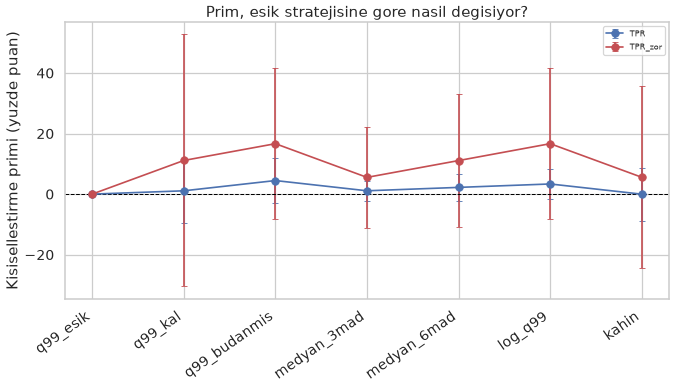


Zor turlerde prim:  mevcut esikte +0.03  |  kahin esikte +5.58
>> Prim esikten bagimsiz. Iki eksen de korunmali.


In [13]:
plt.figure(figsize=(13, 6))
for met, renk in zip(["TPR","TPR_zor"], ["#4c72b0","#c44e52"]):
    a = prim[prim.metrik==met].set_index("strateji").reindex(SIRA)
    plt.errorbar(range(len(a)), a.prim_yuzde_puan, yerr=a["std"],
                 marker="o", lw=2, capsize=4, label=met, color=renk)
plt.axhline(0, color="black", ls="--", lw=1.2)
plt.xticks(range(len(SIRA)), SIRA, rotation=35, ha="right")
plt.ylabel("Kisisellestirme primi (yuzde puan)")
plt.title("Prim, esik stratejisine gore nasil degisiyor?")
plt.legend(fontsize=10)
savefig("f4a_fig04_prim_esige_gore")

mevcut = prim[(prim.strateji=="q99_esik") & (prim.metrik=="TPR_zor")]
enson  = prim[(prim.strateji=="kahin")    & (prim.metrik=="TPR_zor")]
if not mevcut.empty and not enson.empty:
    m = float(mevcut.prim_yuzde_puan.iloc[0]); k = float(enson.prim_yuzde_puan.iloc[0])
    print(f"\nZor turlerde prim:  mevcut esikte {m:+.2f}  |  kahin esikte {k:+.2f}")
    if abs(k) < 0.3*abs(m) if m else False:
        print(">> Prim esik duzeltilince COKUYOR. Asil bulgu esik kalibrasyonudur.")
    elif abs(k) >= abs(m):
        print(">> Prim esikten bagimsiz. Iki eksen de korunmali.")
    else:
        print(">> Prim kismen azaliyor. Ikisi de raporlanmali, oncelik esikte.")

## 6. Soru 5 — Gürültü tabanı

In [14]:
gur = []
for s in SIRA:
    for yap in ["D-D","G-G"]:
        a = strat[(strat.strateji==s)&(strat.yapilandirma==yap)]
        p = a.pivot_table(index="cihaz", columns="tohum", values="TPR_zor")
        if p.shape[1] >= 2:
            gur.append({"strateji": s, "yapilandirma": yap,
                        "tohum_farki_ort": round(100*float((p.iloc[:,0]-p.iloc[:,1]).abs().mean()), 3),
                        "tohum_farki_max": round(100*float((p.iloc[:,0]-p.iloc[:,1]).abs().max()), 3)})
gdf = pd.DataFrame(gur)
gdf.to_csv(f"{OUT}/tables/f4a_tablo5_gurultu.csv", index=False)
print("Iki tohum arasi TPR_zor farki (yuzde puan):\n")
print(gdf.to_string(index=False))
print("\nPrim degerleri bu tabandan buyuk degilse olculemez sayilir.")

Iki tohum arasi TPR_zor farki (yuzde puan):

    strateji yapilandirma  tohum_farki_ort  tohum_farki_max
    q99_esik          D-D            0.003            0.008
    q99_esik          G-G            0.004            0.010
     q99_kal          D-D           11.102           99.895
     q99_kal          G-G           11.106           99.890
q99_budanmis          D-D           33.304           99.903
q99_budanmis          G-G            0.009            0.023
 medyan_3mad          D-D            0.000            0.000
 medyan_3mad          G-G           11.101           99.907
 medyan_6mad          D-D            0.000            0.000
 medyan_6mad          G-G           22.198           99.897
     log_q99          D-D           33.301           99.902
     log_q99          G-G           22.202           99.902
       kahin          D-D           22.204           99.910
       kahin          G-G           11.107           99.890

Prim degerleri bu tabandan buyuk degilse olculemez say

## 7. Özet ve karar

In [15]:
karar = {
    "esik_tanisi": {
        "ortalama_kayma_orani": round(float(ort.kayma_orani.mean()), 3),
        "ortalama_kuyruk_agirligi": round(float(ort.kuyruk_agirligi.mean()), 3),
    },
    "kahin_kazanci": {
        "mevcut_TPR_zor": round(float(kah[kah.esik_tipi.str.startswith("mevcut")].TPR_zor.mean()), 4),
        "kahin_TPR_zor": round(float(kah[kah.esik_tipi.str.startswith("kahin")].TPR_zor.mean()), 4),
    },
    "en_iyi_gercekci_strateji": None,
    "prim_esige_gore": prim[prim.metrik=="TPR_zor"].to_dict("records"),
    "gurultu_tabani": gdf.to_dict("records"),
}
gercekci = oz.drop(index="kahin", errors="ignore")
uygun = gercekci[gercekci.FPR_sapma < 0.02]
if not uygun.empty:
    karar["en_iyi_gercekci_strateji"] = str(uygun.TPR_zor.idxmax())
with open(f"{OUT}/tables/f4a_karar.json","w") as fh:
    json.dump(karar, fh, indent=2, ensure_ascii=False, default=str)
print(json.dumps(karar, indent=2, ensure_ascii=False, default=str))

import shutil
ars = shutil.make_archive(os.path.expanduser("~/work/IoT_Botnet/faz4a_ciktilar"),
                          "zip", OUT)
print("\nArsiv:", ars, f"({os.path.getsize(ars)/1e6:.1f} MB)")

{
  "esik_tanisi": {
    "ortalama_kayma_orani": 1.168,
    "ortalama_kuyruk_agirligi": 188.672
  },
  "kahin_kazanci": {
    "mevcut_TPR_zor": 0.1117,
    "kahin_TPR_zor": 0.2228
  },
  "en_iyi_gercekci_strateji": "log_q99",
  "prim_esige_gore": [
    {
      "strateji": "q99_esik",
      "metrik": "TPR_zor",
      "prim_yuzde_puan": 0.031,
      "std": 0.019,
      "p_ttest": 0.0014,
      "p_wilcoxon": 0.0039,
      "D-D kazandi": 9,
      "n": 9
    },
    {
      "strateji": "q99_kal",
      "metrik": "TPR_zor",
      "prim_yuzde_puan": 11.137,
      "std": 41.627,
      "p_ttest": 0.4454,
      "p_wilcoxon": 0.1094,
      "D-D kazandi": 7,
      "n": 9
    },
    {
      "strateji": "q99_budanmis",
      "metrik": "TPR_zor",
      "prim_yuzde_puan": 16.681,
      "std": 24.974,
      "p_ttest": 0.08,
      "p_wilcoxon": 0.0078,
      "D-D kazandi": 8,
      "n": 9
    },
    {
      "strateji": "medyan_3mad",
      "metrik": "TPR_zor",
      "prim_yuzde_puan": 5.552,
      "std":

---

## Karar kuralları

| Gözlem | Sonuç |
|---|---|
| Kahin eşiği zor türlerde TPR'yi 0,11'den 0,9 üzerine çıkarıyor | Eşik çalışması değerli, ana eksen olur |
| Gerçekçi bir strateji kahine yakın, FPR hedefte | Somut çözüm önerimiz var |
| Prim kahin eşiğinde çöküyor | Kişiselleştirme destekleyici bölüme iner |
| Prim tüm eşiklerde duruyor | İki bağımsız katkı, ikisi de korunur |
| Kayma oranı 1'den belirgin büyük | Kaymaya dayanıklı eşik gerekçelendirilir |
| Kuyruk ağırlığı büyük ama kayma yok | Dayanıklı istatistik (MAD) yeterli |